In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid", context="notebook", palette="deep")

# train_x columns: x, y, in_residential_area
train_x = np.loadtxt("train_x.csv", delimiter=",", skiprows=1)
train_y = np.loadtxt("train_y.csv", delimiter=",", skiprows=1)

df = pd.DataFrame({
    "x": train_x[:, 0],
    "y": train_x[:, 1],
    "residential": train_x[:, 2].astype(bool),
    "pm25": train_y,
})
df["area"] = df["residential"].map({True: "Residential candidate", False: "Other"})

display(df.describe())

,x,y,pm25
count,15189.000000,15189.000000,15189.000000
mean,0.473093,0.572626,33.172998
std,0.280767,0.277542,18.514441
min,0.000000,0.000000,-1.762547
25%,0.253750,0.346250,14.918420
50%,0.433750,0.636250,37.081295
75%,0.717500,0.805000,50.033085
max,0.998750,0.998750,64.896184


In [20]:
df["area"].value_counts()

area
Other                    8186
Residential candidate    7003
Name: count, dtype: int64

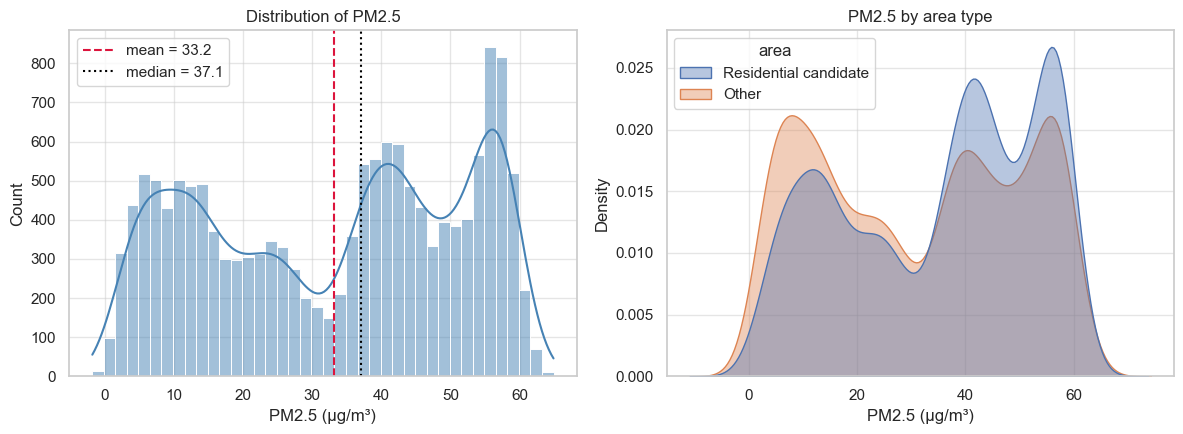

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.histplot(df["pm25"], bins=40, kde=True, color="steelblue", ax=axes[0])
axes[0].axvline(df["pm25"].mean(), color="crimson", ls="--",
                label=f"mean = {df['pm25'].mean():.1f}")
axes[0].axvline(df["pm25"].median(), color="black", ls=":",
                label=f"median = {df['pm25'].median():.1f}")
axes[0].set(title="Distribution of PM2.5", xlabel="PM2.5 (µg/m³)", ylabel="Count")
axes[0].legend()

sns.kdeplot(data=df, x="pm25", hue="area", fill=True, common_norm=False,
            alpha=0.4, ax=axes[1])
axes[1].set(title="PM2.5 by area type", xlabel="PM2.5 (µg/m³)")

plt.tight_layout()
plt.show()

There are certain spikes in the distribution of PM2.5.

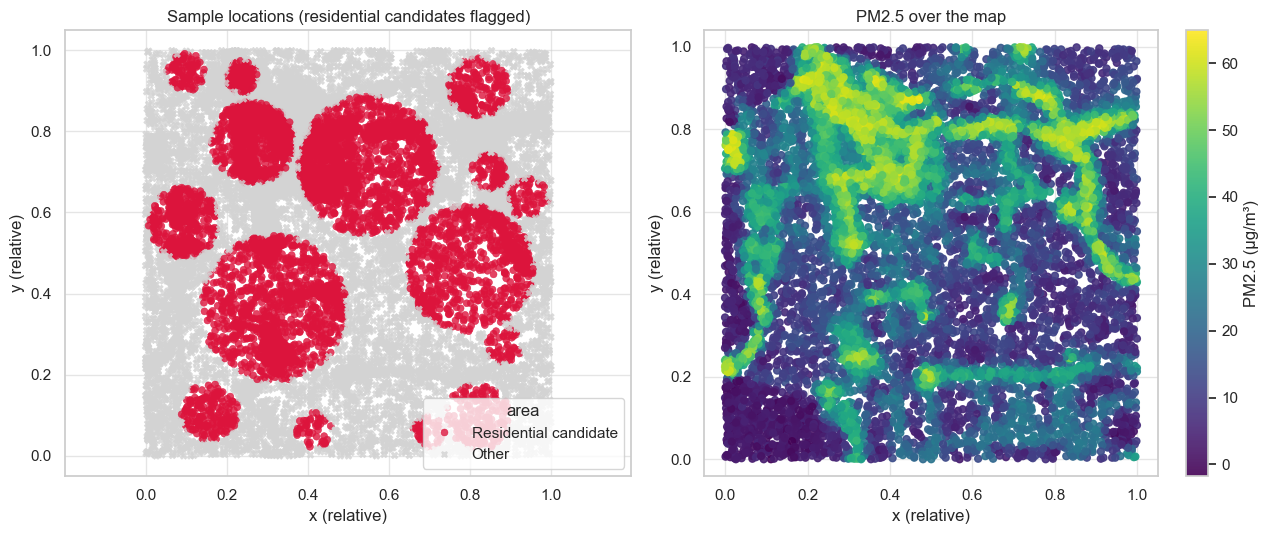

In [22]:
SHOW_FLAGGED = False   # set to False to hide the red highlighting

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# (a) sample locations
sns.scatterplot(data=df, x="x", y="y", hue="area", style="area",
                palette={"Other": "lightgray", "Residential candidate": "crimson"},
                s=25, alpha=0.8, edgecolor=None, ax=axes[0])
axes[0].set_title("Sample locations (residential candidates flagged)")
axes[0].set(xlabel="x (relative)", ylabel="y (relative)")
axes[0].set_aspect("equal", adjustable="datalim")

# (b) coloured by PM2.5
sc = axes[1].scatter(df["x"], df["y"], c=df["pm25"], cmap="viridis", s=25, alpha=0.9)
if SHOW_FLAGGED:
    flag = df[df["residential"]]
    axes[1].scatter(flag["x"], flag["y"], facecolors="none", edgecolors="red",
                    s=60, linewidths=0.8, label="Residential candidate")
    axes[1].legend(loc="upper right")
plt.colorbar(sc, ax=axes[1], label="PM2.5 (µg/m³)")
axes[1].set(title="PM2.5 over the map", xlabel="x (relative)", ylabel="y (relative)")
axes[1].set_aspect("equal", adjustable="datalim")

plt.tight_layout()
plt.show()

In [23]:
from sklearn.cluster import KMeans

km = KMeans(n_clusters=10, n_init=10, random_state=0).fit(train_x[:, :2])
labels = km.labels_

# representative subsample: the point closest to each centroid
idx = [np.argmin(np.linalg.norm(train_x[:, :2] - c, axis=1)) for c in km.cluster_centers_]

/var/folders/jt/1ryntwrd2lg2mrgmq5nj2y080000gn/T/ipykernel_17329/2773084774.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="cluster", y="pm25", palette=palette, ax=axes[1])


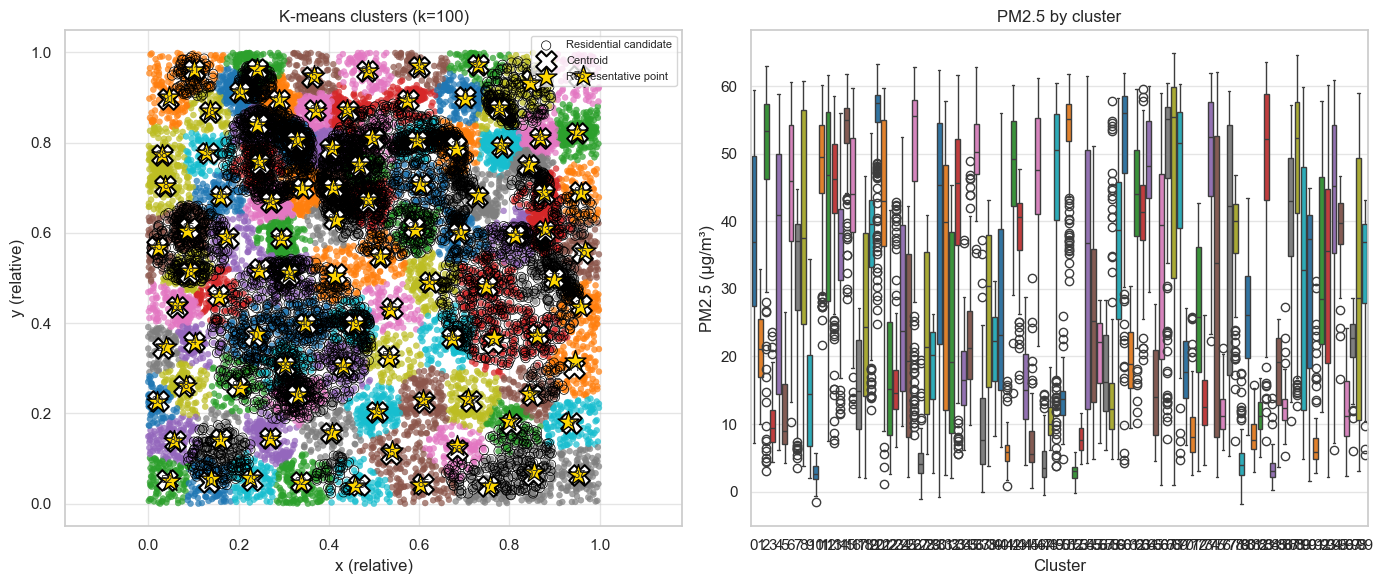

,count,mean,std
cluster,,,
0,174,37.78,13.34
1,107,21.38,4.99
2,241,49.23,12.56
3,78,10.40,4.20
4,129,34.64,17.30
...,...,...,...
95,192,39.19,4.46
96,92,12.12,4.97
97,106,21.88,4.10


In [25]:
from sklearn.cluster import KMeans

K = 100
km = KMeans(n_clusters=K, n_init=10, random_state=0).fit(train_x[:, :2])
labels = km.labels_

# representative subsample: the point closest to each centroid
idx = [np.argmin(np.linalg.norm(train_x[:, :2] - c, axis=1)) for c in km.cluster_centers_]

df["cluster"] = labels
SHOW_FLAGGED = True   # outline residential candidates

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# (a) points colored by cluster, centroids and representatives marked
palette = sns.color_palette("tab10", K)
sns.scatterplot(data=df, x="x", y="y", hue="cluster", palette=palette,
                s=18, alpha=0.7, edgecolor=None, legend=False, ax=axes[0])
if SHOW_FLAGGED:
    flag = df[df["residential"]]
    axes[0].scatter(flag["x"], flag["y"], facecolors="none", edgecolors="black",
                    s=45, linewidths=0.5, label="Residential candidate")
axes[0].scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1],
                marker="X", s=220, c="white", edgecolors="black", linewidths=1.5,
                label="Centroid", zorder=5)
axes[0].scatter(df["x"].iloc[idx], df["y"].iloc[idx],
                marker="*", s=250, c="gold", edgecolors="black", linewidths=1,
                label="Representative point", zorder=6)
for k, (cx, cy) in enumerate(km.cluster_centers_):
    axes[0].text(cx, cy, str(k), ha="center", va="center", fontsize=8, zorder=7)
axes[0].set(title=f"K-means clusters (k={K})", xlabel="x (relative)", ylabel="y (relative)")
axes[0].set_aspect("equal", adjustable="datalim")
axes[0].legend(loc="upper right", fontsize=8)

# (b) PM2.5 per cluster: do regions differ in level or spread?
sns.boxplot(data=df, x="cluster", y="pm25", palette=palette, ax=axes[1])
axes[1].set(title="PM2.5 by cluster", xlabel="Cluster", ylabel="PM2.5 (µg/m³)")

plt.tight_layout()
plt.show()

display(df.groupby("cluster")["pm25"].agg(["count", "mean", "std"]).round(2))